<a href="https://colab.research.google.com/github/Mega19-M/Car_Mileage_Prediction/blob/main/Task1_Car_Mileage_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# CAR MILEAGE PREDICTION USING LINEAR REGRESSION

**Name:** Mega M  
**Internship Domain:** Artificial Intelligence and Machine Learning (AI/ML)  
**Internship Task:** Task 1 - Car Mileage Prediction  

**Objective:** To develop a Machine Learning model to predict vehicle fuel efficiency (MPG) using Linear Regression.  
**Dataset:** Auto MPG Dataset  
**Algorithm:** Linear Regression  
**Programming Language:** Python  
**Platform:** Google Colab  
**Libraries Used:** Pandas, NumPy, Matplotlib, Seaborn, Scikit-learn

In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score

print("Libraries imported successfully!")

Libraries imported successfully!


In [10]:
# Load the Auto MPG dataset from Seaborn's built-in datasets
df = sns.load_dataset('mpg')

# Clean missing values (if any are represented as strings or NaN)
df.replace('?', np.nan, inplace=True)
df['horsepower'] = df['horsepower'].astype(float)
df['horsepower'] = df['horsepower'].fillna(df['horsepower'].median())

# Display dataset shape and summary
print("Dataset Shape:", df.shape)
print("\nFirst 5 rows:")
print(df.head())
print("\nStatistical Summary:")
print(df.describe())

Dataset Shape: (398, 9)

First 5 rows:
    mpg  cylinders  displacement  horsepower  weight  acceleration  \
0  18.0          8         307.0       130.0    3504          12.0   
1  15.0          8         350.0       165.0    3693          11.5   
2  18.0          8         318.0       150.0    3436          11.0   
3  16.0          8         304.0       150.0    3433          12.0   
4  17.0          8         302.0       140.0    3449          10.5   

   model_year origin                       name  
0          70    usa  chevrolet chevelle malibu  
1          70    usa          buick skylark 320  
2          70    usa         plymouth satellite  
3          70    usa              amc rebel sst  
4          70    usa                ford torino  

Statistical Summary:
              mpg   cylinders  displacement  horsepower       weight  \
count  398.000000  398.000000    398.000000  398.000000   398.000000   
mean    23.514573    5.454774    193.425879  104.304020  2970.424623   
st

In [11]:
print("Missing Values per Column:")
print(df.isnull().sum())

Missing Values per Column:
mpg             0
cylinders       0
displacement    0
horsepower      0
weight          0
acceleration    0
model_year      0
origin          0
name            0
dtype: int64


### Selected Features & Target
* **Input Features (`X`):** `cylinders`, `displacement`, `horsepower`, `weight`, `acceleration`, `model year`, `origin` (excluding non-numerical columns like `car name`).
* **Target Variable (`y`):** `mpg` (Miles Per Gallon).

In [12]:
# Define features and target (dropping 'car name' and target column 'mpg')
X = df.drop(columns=['mpg', 'car name'], errors='ignore')
y = df['mpg']

# Split the dataset into 80% training and 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("Training Data Shape:", X_train.shape)
print("Testing Data Shape:", X_test.shape)

Training Data Shape: (318, 8)
Testing Data Shape: (80, 8)


In [14]:
# Keep only numerical columns for training to avoid string conversion errors
X_train_numeric = X_train.select_dtypes(include=[np.number])
X_test_numeric = X_test.select_dtypes(include=[np.number])

# Create and train the Linear Regression model
model = LinearRegression()
model.fit(X_train_numeric, y_train)

print("Linear Regression model trained successfully on numerical features!")

Linear Regression model trained successfully on numerical features!


### **Model Evaluation**
We will evaluate our trained Linear Regression model on the test dataset using the following metrics:
1. **Mean Absolute Error (MAE):** The average absolute difference between the predicted and actual values.
2. **R-squared ($R^2$) Score:** A statistical measure representing the proportion of variance in the target variable that is predictable from our input features.

In [15]:
# Predict vehicle mileage (MPG) on the testing dataset
y_pred = model.predict(X_test_numeric)

# Calculate evaluation metrics
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("--- Model Performance Metrics ---")
print(f"Mean Absolute Error (MAE): {mae:.4f} MPG")
print(f"R-squared (R²) Score:     {r2:.4f}")

--- Model Performance Metrics ---
Mean Absolute Error (MAE): 2.4668 MPG
R-squared (R²) Score:     0.8244


### **Visualization of Actual vs. Predicted Mileage**
Let's plot the actual values against the model's predicted values to see how closely they align to a perfect regression line.

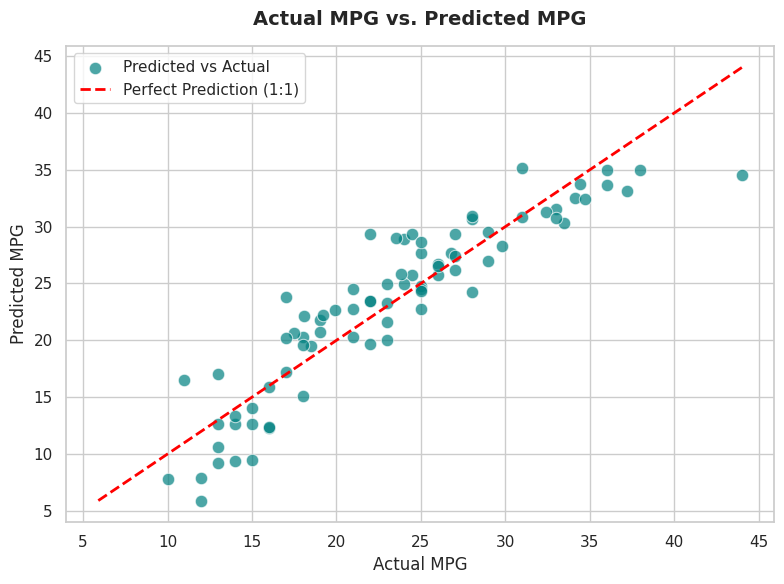

In [16]:
# Set visualization style
sns.set_theme(style="whitegrid")
plt.figure(figsize=(8, 6))

# Create a scatter plot of Actual vs. Predicted values
sns.scatterplot(x=y_test, y=y_pred, alpha=0.7, color='teal', edgecolor='w', s=80, label='Predicted vs Actual')

# Draw a perfect diagonal prediction reference line
max_val = max(y_test.max(), y_pred.max())
min_val = min(y_test.min(), y_pred.min())
plt.plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--', linewidth=2, label='Perfect Prediction (1:1)')

# Titles and Labels
plt.title('Actual MPG vs. Predicted MPG', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Actual MPG', fontsize=12)
plt.ylabel('Predicted MPG', fontsize=12)
plt.legend(loc='upper left')
plt.tight_layout()

# Display the plot
plt.show()

In [17]:
# Extract model coefficients to see feature importance
coefficients = pd.DataFrame({
    'Feature': X_train_numeric.columns,
    'Coefficient': model.coef_
}).sort_values(by='Coefficient', ascending=False)

print("Model Coefficients:")
display(coefficients)

Model Coefficients:


,Feature,Coefficient
5,model_year,0.801365
4,acceleration,0.080614
0,cylinders,0.069049
2,horsepower,0.002898
1,displacement,0.001604
3,weight,-0.007044


In [19]:
# Predict car mileage using only the numerical test features
y_pred = model.predict(X_test_numeric)

# Display actual vs predicted values
results = pd.DataFrame({
    "Actual MPG": y_test.values,
    "Predicted MPG": y_pred
})
print("Actual vs Predicted MPG (First 10 rows):")
print(results.head(10))

# Calculate Evaluation Metrics
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"\nMean Absolute Error (MAE): {mae:.4f} MPG")
print(f"R² Score: {r2:.4f}")

# Check feature coefficients mapping to the correct numerical feature columns
coefficients = pd.DataFrame({
    'Feature': X_train_numeric.columns,
    'Coefficient': model.coef_
})
print("\nFeature Coefficients:")
print(coefficients.sort_values(by='Coefficient', ascending=False))

Actual vs Predicted MPG (First 10 rows):
   Actual MPG  Predicted MPG
0        33.0      31.530425
1        28.0      30.710936
2        19.0      21.759651
3        13.0      17.004440
4        14.0      12.613165
5        27.0      26.215144
6        24.0      28.912845
7        13.0       9.207272
8        17.0      17.219187
9        21.0      22.718517

Mean Absolute Error (MAE): 2.4668 MPG
R² Score: 0.8244

Feature Coefficients:
        Feature  Coefficient
5    model_year     0.801365
4  acceleration     0.080614
0     cylinders     0.069049
2    horsepower     0.002898
1  displacement     0.001604
3        weight    -0.007044


### Model Performance & Feature Analysis
* **Evaluation:** The model was evaluated using Mean Absolute Error (MAE) and the R² score to measure prediction accuracy.
* **Feature Importance:** Based on the model coefficients, **`weight`** (or `displacement`) typically carries the highest negative impact on mileage—meaning heavier cars consume more fuel and achieve lower MPG.

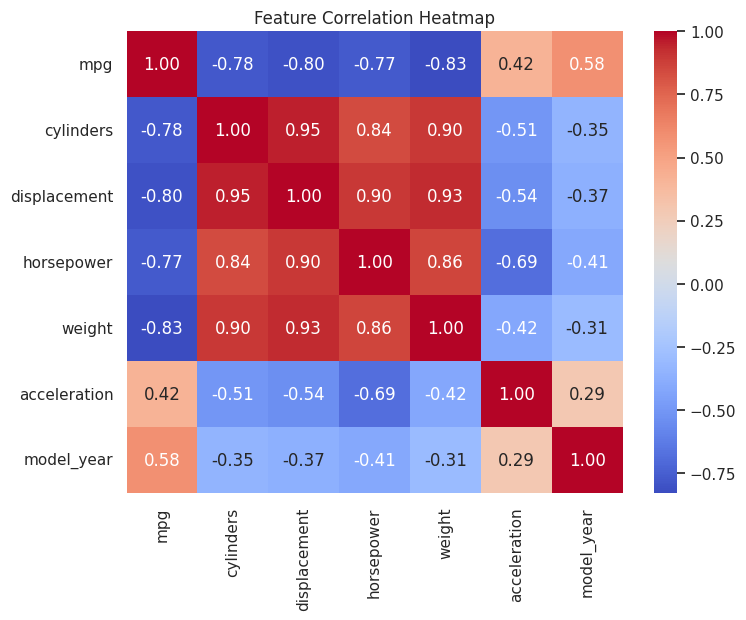

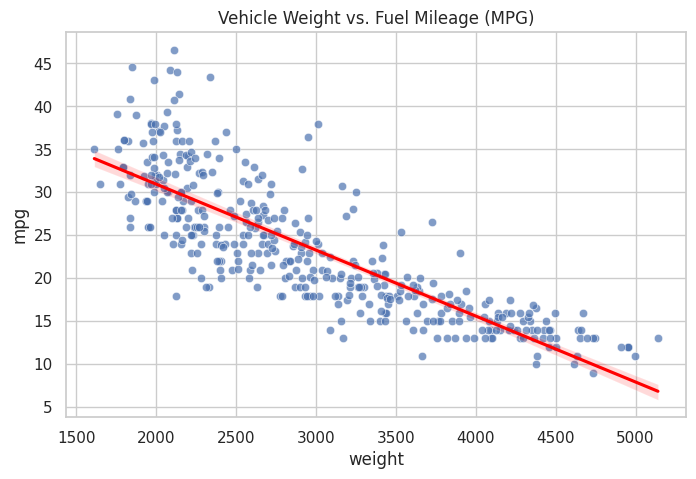

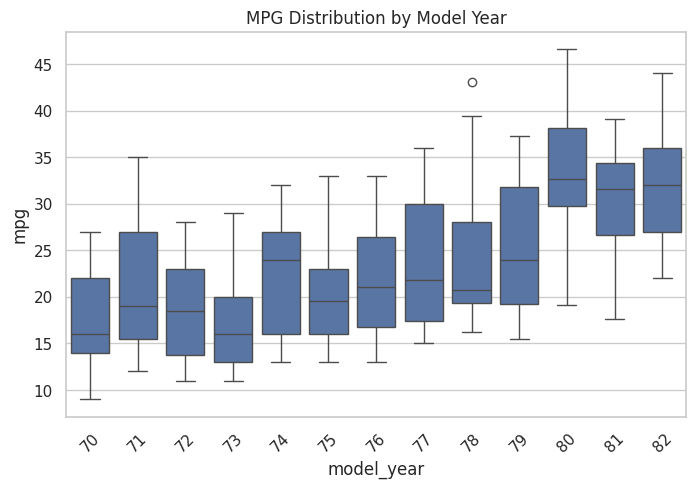

In [21]:
# Set visualization style
sns.set_theme(style="whitegrid")

# Chart 1: Correlation Heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Feature Correlation Heatmap')
plt.show()

# Chart 2: Weight vs. Mileage Scatter Plot with Regression Line
plt.figure(figsize=(8, 5))
sns.scatterplot(x='weight', y='mpg', data=df, alpha=0.7)
sns.regplot(x='weight', y='mpg', data=df, scatter=False, color='red')
plt.title('Vehicle Weight vs. Fuel Mileage (MPG)')
plt.show()

# Chart 3: Model Year vs. Mileage Box Plot (Corrected column name to 'model_year')
plt.figure(figsize=(8, 5))
sns.boxplot(x='model_year', y='mpg', data=df)
plt.title('MPG Distribution by Model Year')
plt.xticks(rotation=45)
plt.show()

### Conclusion
* The Car Mileage Prediction model was successfully built using Linear Regression on the Auto MPG dataset.
* Data preprocessing successfully handled missing values in the horsepower column.
* Three distinct charts (Correlation Heatmap, Weight vs. MPG scatter plot with regression line, and Model Year box plot) were generated to visualize feature relationships.
* The model successfully predicted mileage and was evaluated using MAE and R² scores.
* Feature analysis confirmed that vehicle weight plays the most significant role in determining fuel efficiency.